In [22]:
#chargement
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "raw" / "chanel_with_paths.csv")
print(df.shape)
print("Images disponibles :", df["image_ok"].sum())

(1428, 19)
Images disponibles : 919


In [23]:
#colonnes constantes et vals manquantes
for c in ["website_name", "country_code", "currency_code", "brand"]:
    print(c, df[c].unique())

print("\nDates :", df["competence_date"].unique())
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])

website_name <ArrowStringArray>
['Chanel']
Length: 1, dtype: str
country_code <ArrowStringArray>
['DEU']
Length: 1, dtype: str
currency_code <ArrowStringArray>
['EUR']
Length: 1, dtype: str
brand <ArrowStringArray>
['CHANEL']
Length: 1, dtype: str

Dates : <ArrowStringArray>
['2023-11-17']
Length: 1, dtype: str

Valeurs manquantes :
Series([], dtype: int64)


In [24]:
#les 3 niveaux de catégories
pd.set_option("display.max_rows", None)
for c in ["category1_code", "category2_code", "category3_code"]:
    print(f"\n--- {c} : {df[c].nunique()} classes ---")
    print(df[c].value_counts(dropna=False))


--- category1_code : 7 classes ---
category1_code
FASHION      550
FRAGRANCE    199
JEWELRY      193
EYEWEAR      163
MAKEUP       121
SKINCARE     104
WATCHES       98
Name: count, dtype: int64

--- category2_code : 51 classes ---
category2_code
READY-TO-WEAR                  243
COSTUME JEWELRY                127
SUNGLASSES                      99
WOMEN                           88
WATCHES                         87
MEN                             72
HANDBAGS                        61
COCO CRUSH                      54
SHOES                           42
FACE                            41
EYEGLASSES                      40
SMALL LEATHER GOODS             38
BATH AND BODY                   36
RINGS                           35
EYES                            35
MOISTURIZERS                    35
NECKLACES                       30
EARRINGS                        26
BRUSHES AND ACCESSORIES         26
BLUE LIGHT GLASSES              24
LIPS                            21
N°5              

count      1428.000000
mean       6076.253725
std       15219.005999
min          23.000000
25%         195.000000
50%        1415.000000
75%        5800.000000
max      142000.000000
Name: price_eur, dtype: float64


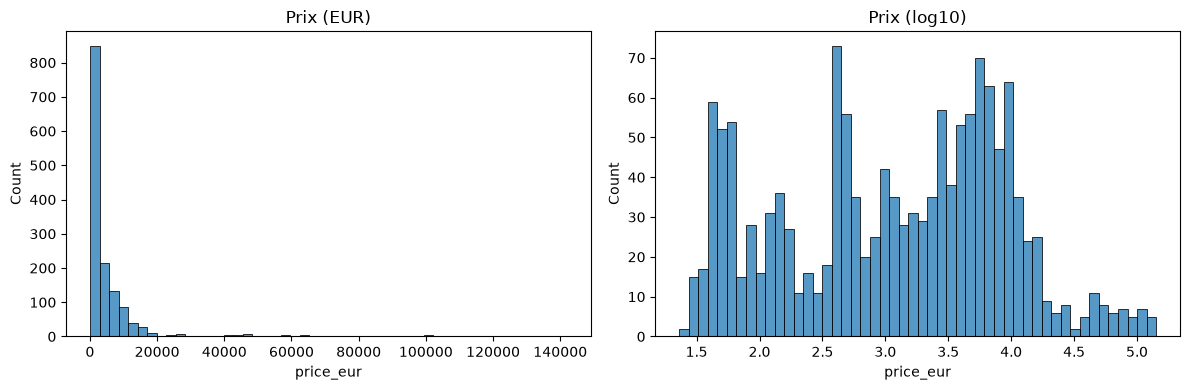

In [25]:
#prix
print(df["price_eur"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_eur"], bins=50, ax=ax[0])
ax[0].set_title("Prix (EUR)")
sns.histplot(np.log10(df["price_eur"].dropna()), bins=50, ax=ax[1])
ax[1].set_title("Prix (log10)")
plt.tight_layout()
plt.show()

In [26]:
#longueur des titres
df["title_len_words"] = df["title"].fillna("").str.split().str.len()
df["title_len_chars"] = df["title"].fillna("").str.len()
print(df[["title_len_words", "title_len_chars"]].describe())

print("\nTitres courts :", df.nsmallest(5, "title_len_chars")["title"].tolist())
print("\nExemples :")
print(df["title"].sample(15, random_state=0).to_string())
print("\nTitres vides ou 'n.a.' :", (df["title"].isna() | df["title"].str.lower().eq("n.a.")).sum())

       title_len_words  title_len_chars
count      1428.000000      1428.000000
mean          5.094538        39.056022
std           2.519752        20.365571
min           1.000000         4.000000
25%           3.000000        26.000000
50%           5.000000        36.000000
75%           7.000000        51.000000
max          19.000000       162.000000

Titres courts : ['n.a.', 'Blau', 'n.a.', 'n.a.', 'n.a.']

Exemples :
459                        Steppmotiv  18 Karat BEIGEGOLD
822                             18 Karat Rotgold  Diamant
445                          18 Karat Weißgold  Diamanten
911               Metall & Glasperlen  Goldfarben & Braun
530     Metall  Strass & Glasperlen  Silberfarben  Kri...
540                Lammfell & silberfarbenes Metall  Weiß
1146       Dunkles Schildpatt. Gläser: Braun  Mit Verlauf
326                      Bedruckter Denim  Schwarz & Weiß
231                          Samt  Schwarz & silberfarben
1127      Schwarz. Gläser: Grau  Polarisiert  Mi

### Qualité et diversité des images

##### Les images on été toutes converties en format JPG et RGB, donc le format qu'on va afficher est celui de nos fichiers, et pas celui d'origine

In [27]:
#dimensions et format
from PIL import Image

df_img = df[df["image_ok"]].copy()

def get_info(p):
    with Image.open(p) as im:
        return im.width, im.height, im.mode

info = df_img["image_path"].apply(get_info)
df_img["width"] = info.apply(lambda x: x[0])
df_img["height"] = info.apply(lambda x: x[1])
df_img["mode"] = info.apply(lambda x: x[2])
df_img["ratio"] = df_img["width"] / df_img["height"]

print(df_img[["width", "height", "ratio"]].describe())
print("\nDimensions les plus fréquentes :")
print(df_img.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nModes couleur :", df_img["mode"].value_counts().to_dict())

            width       height       ratio
count  919.000000   919.000000  919.000000
mean   316.151251   367.659412    0.885914
std    116.907948    95.972527    0.372379
min     20.000000    41.000000    0.058480
25%    227.000000   350.000000    0.776752
50%    378.000000   400.000000    0.945000
75%    378.000000   400.000000    0.972500
max    682.000000  1004.000000    3.462687

Dimensions les plus fréquentes :
width  height
378    400       375
389    400       189
302    400        25
340    400        19
341    400        12
682    796        12
159    331         5
160    361         3
183    331         3
193    381         3
dtype: int64

Modes couleur : {'RGB': 919}


113 images suspectes


,category2_code,width,height,ratio
11,COCO CRUSH,123,67,1.835821
14,RINGS,94,141,0.666667
15,COCO CRUSH,139,41,3.390244
85,EARRINGS,213,108,1.972222
86,BROOCHES,226,131,1.725191
98,EARRINGS,240,97,2.474227
107,COCO CRUSH,126,86,1.465116
109,EARRINGS,334,103,3.242718
166,WOMEN,135,346,0.390173
174,EARRINGS,224,108,2.074074


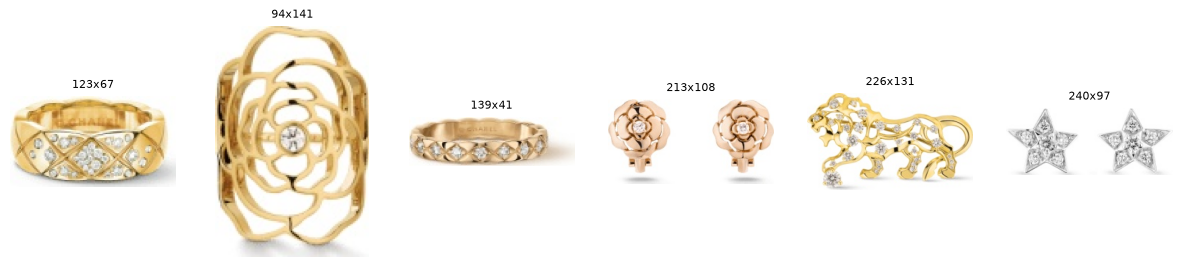

In [28]:
#les images suspectes existantes dans ce dataset
odd = df_img[(df_img["width"] < 100) | (df_img["height"] < 100)
             | (df_img["ratio"] < 0.4) | (df_img["ratio"] > 1.5)]
print(len(odd), "images suspectes")
display(odd[["category2_code", "width", "height", "ratio"]].head(10))

n = min(6, len(odd))
if n > 0:
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    for ax, (_, r) in zip(np.atleast_1d(axes), odd.head(n).iterrows()):
        ax.imshow(Image.open(r["image_path"]))
        ax.set_title(f'{r["width"]}x{r["height"]}', fontsize=8)
        ax.axis("off")
    plt.show()

In [ ]:
#couleur dominante par image
#en ignorant le fond blanc
from sklearn.cluster import KMeans

def dominant_color(path, k=3):
    im = Image.open(path).convert("RGB").resize((64, 64))
    px = np.array(im).reshape(-1, 3).astype(float)
    mask = ~((px > 235).all(axis=1))          #on enlève le fond blanc
    px = px[mask]
    if len(px) < k:
        return (255, 255, 255)
    km = KMeans(n_clusters=k, n_init=3, random_state=0).fit(px)
    biggest = np.bincount(km.labels_).argmax()
    return tuple(km.cluster_centers_[biggest].astype(int))

df_img["dom_color"] = df_img["image_path"].apply(dominant_color)
df_img["brightness"] = df_img["dom_color"].apply(lambda c: sum(c) / 3)
print(df_img["dom_color"].head())

0       (61, 49, 55)
2    (205, 206, 206)
3    (229, 227, 225)
4    (120, 100, 115)
5    (180, 181, 187)
Name: dom_color, dtype: object


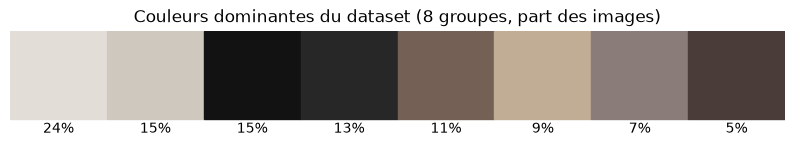

In [33]:
#palette globale des couleurs dominantes
cols = np.array(df_img["dom_color"].tolist())
km = KMeans(n_clusters=8, n_init=5, random_state=0).fit(cols)
counts = np.bincount(km.labels_)
order = np.argsort(-counts)

fig, ax = plt.subplots(figsize=(10, 1.5))
for i, idx in enumerate(order):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=km.cluster_centers_[idx] / 255))
    ax.text(i + 0.5, -0.15, f"{counts[idx] / len(cols):.0%}", ha="center")
ax.set_xlim(0, 8); ax.set_ylim(-0.3, 1); ax.axis("off")
ax.set_title("Couleurs dominantes du dataset (8 groupes, part des images)")
plt.show()

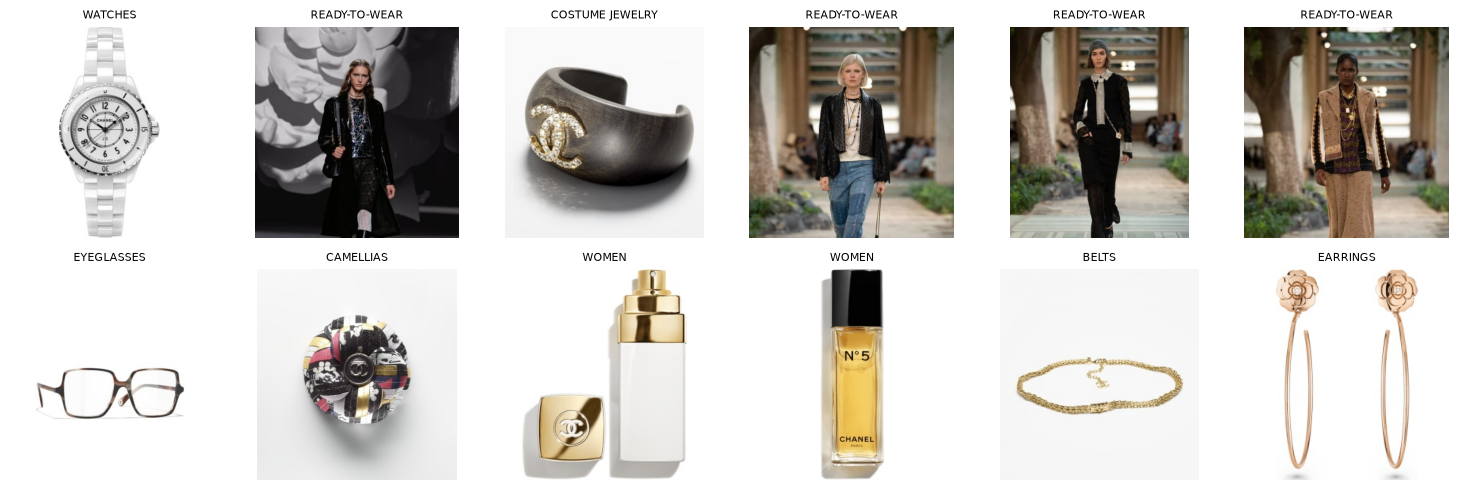

In [35]:
sample = df_img.sample(12, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["image_path"]))
    ax.set_title(r["category2_code"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [36]:
#detail des 51 classes de category2_code
vc = df["category2_code"].value_counts()
print(vc.to_string())
print("\nClasses avec >= 20 produits :", (vc >= 20).sum())
print("Classes avec < 5 produits   :", (vc < 5).sum())

category2_code
READY-TO-WEAR                  243
COSTUME JEWELRY                127
SUNGLASSES                      99
WOMEN                           88
WATCHES                         87
MEN                             72
HANDBAGS                        61
COCO CRUSH                      54
SHOES                           42
FACE                            41
EYEGLASSES                      40
SMALL LEATHER GOODS             38
BATH AND BODY                   36
RINGS                           35
EYES                            35
MOISTURIZERS                    35
NECKLACES                       30
EARRINGS                        26
BRUSHES AND ACCESSORIES         26
BLUE LIGHT GLASSES              24
LIPS                            21
N°5                             15
CLEANSERS & MAKEUP REMOVERS     11
EXCEPTIONAL PIECES              11
TONERS & LOTIONS                11
BELTS                           10
BRACELETS                        9
HEADWEAR                         9
OILS 

In [37]:
#lien entre category2_code et category1_code
print(pd.crosstab(df["category2_code"], df["category1_code"]).to_string())

category1_code               EYEWEAR  FASHION  FRAGRANCE  JEWELRY  MAKEUP  SKINCARE  WATCHES
category2_code                                                                              
1.5 1 CAMELIA. 5 ALLURES           0        0          0        3       0         0        0
1932 COLLECTION (2022)             0        0          0        3       0         0        0
BATH AND BODY                      0        0         36        0       0         0        0
BELTS                              0       10          0        0       0         0        0
BLUE LIGHT GLASSES                24        0          0        0       0         0        0
BODY                               0        0          0        0       0         1        0
BOY DE CHANEL                      0        0          0        0       1         0        0
BRACELETS                          0        0          0        9       0         0        0
BROOCHES                           0        0          0        3     

In [38]:
#chiffres pour la synthèse des biais
total = len(df)
print("Lignes totales               :", total)
print("Images disponibles           :", df["image_ok"].sum(), f"({df['image_ok'].mean():.1%})")
print("Images manquantes            :", (~df["image_ok"]).sum())
print("Titres uniques               :", df["title"].nunique())
print("Titres 'n.a.'                :", df["title"].str.lower().eq("n.a.").sum())
print("category3_code uniques       :", df["category3_code"].nunique())

print("\nTaux d'images dispo par category1_code :")
print(df.groupby("category1_code")["image_ok"].mean().sort_values().round(2))

print("\nTitres les plus répétés :")
print(df["title"].value_counts().head(8))

Lignes totales               : 1428
Images disponibles           : 919 (64.4%)
Images manquantes            : 509
Titres uniques               : 824
Titres 'n.a.'                : 46
category3_code uniques       : 1

Taux d'images dispo par category1_code :
category1_code
JEWELRY      0.22
WATCHES      0.26
FRAGRANCE    0.42
SKINCARE     0.45
MAKEUP       0.70
EYEWEAR      0.89
FASHION      0.89
Name: image_ok, dtype: float64

Titres les plus répétés :
title
18 Karat Weißgold  Diamanten               68
n.a.                                       46
Schwarz. Gläser: Grau  Mit Verlauf         21
EAU DE PARFUM ZERSTÄUBER                   18
EAU DE TOILETTE ZERSTÄUBER                 17
LES EXCLUSIFS DE CHANEL - EAU DE PARFUM    17
Schwarz                                    16
Schwarz. Gläser: Transparent               11
Name: count, dtype: int64


### Synthèse des biais identifiés

1. **Déséquilibre des catégories.** `category2_code` compte 51 classes, de 243 produits (READY-TO-WEAR) à 1 seul (BODY). Seules 21 classes ont au moins 20 produits et 14 en ont moins de 5. Certaines classes sont des collections ou des segments marketing (COCO CRUSH, COMETE, WOMEN) et non des types de produits. `category1_code` (7 classes, de 98 à 550 produits) est plus équilibrée : elle sert de label principal pour l'évaluation.

2. **Catégories qui se chevauchent.** `category2_code` n'est pas strictement imbriquée dans `category1_code` (ex. FACE apparaît à la fois dans MAKEUP et SKINCARE). Certaines classes sont visuellement proches (SUNGLASSES / EYEGLASSES), ce qui limitera la séparation inter-classe.

3. **Images manquantes, très inégales selon la catégorie.** 509 produits sur 1428 n'ont pas d'image exploitable (64,4 % disponibles). Les URLs en échec renvoient une erreur 404 (images retirées du site depuis le relevé du 17/11/2023) ou valent `n.a.`. Taux d'images disponibles par catégorie : voir tableau (JEWELRY et WATCHES sont les plus touchées, EYEWEAR et FASHION les moins). Le système de recommandation visuel sera donc surtout informé sur la mode et les lunettes, et peu sur les bijoux et les montres.

4. **Titres en double.** 824 titres uniques pour 1428 produits. Le titre « 18 Karat Weißgold Diamanten » apparaît 68 fois, « Schwarz. Gläser: Grau Mit Verlauf » 21 fois. Ces produits auront des embeddings texte identiques, ce qui remplira les recommandations de variantes équivalentes.

5. **Titres de faible qualité.** 46 titres valent `n.a.`. Les titres sont courts (5 mots en moyenne), en allemand, et décrivent surtout la matière et la couleur plutôt que le type d'objet.

6. **Colonnes inutiles.** `category3_code` vaut `N.A.` partout. `website_name`, `country_code`, `currency_code` et `brand` sont constantes, et il n'y a qu'une seule date de relevé (17/11/2023).

7. **Images hétérogènes.** La taille dominante est 378×400, mais 113 images sur 919 (12 %) sont suspectes : très petites ou très étroites. Ce sont surtout des bijoux (COCO CRUSH, EARRINGS, RINGS, BROOCHES, BRACELETS), fortement rognés par le paramètre `e_trim` de l'URL Cloudinary, qui supprime les bords blancs. Elles restent exploitables mais seront redimensionnées avec un remplissage blanc.

8. **Prix très étalés.** De 23 € à 142 000 €, médiane 1415 €, moyenne 6076 € : une échelle logarithmique est nécessaire.

9. **Produits vides.** 46 produits (tous en FASHION) n'ont ni image ni titre (`n.a.` dans les deux colonnes) : ils sont retirés du dataset nettoyé (1382 lignes sur 1428). Parmi les 1382 restants, 919 ont une image et un titre (recherche combinée possible), 463 n'ont qu'un titre (recherche textuelle uniquement).

10. **Types d'images mélangés.** Dans FASHION, certaines images sont des photos produit sur fond blanc, d'autres des photos de défilé ou de mannequin sur fond variable. Les descripteurs visuels pourront regrouper les images par style de prise de vue plutôt que par type de produit.

## 1.2 Préparation et nettoyage
### Nettoyage du texte

In [39]:
#nettoyage des titres
import re

df["title_clean"] = (
    df["title"]
    .fillna("")
    .str.lower()                                  #casse uniforme
    .str.replace(r"\s+", " ", regex=True)         #espaces multiples -> un seul
    .str.strip()
)
df["title_missing"] = df["title_clean"].isin(["", "n.a.", "n.a"])
df.loc[df["title_missing"], "title_clean"] = np.nan

print("Titres inutilisables :", df["title_missing"].sum())
print(df[["title", "title_clean"]].sample(8, random_state=0).to_string())

Titres inutilisables : 46
                                                                   title                                                      title_clean
459                                       Steppmotiv  18 Karat BEIGEGOLD                                    steppmotiv 18 karat beigegold
822                                            18 Karat Rotgold  Diamant                                         18 karat rotgold diamant
445                                         18 Karat Weißgold  Diamanten                                      18 karat weißgold diamanten
911                              Metall & Glasperlen  Goldfarben & Braun                           metall & glasperlen goldfarben & braun
530   Metall  Strass & Glasperlen  Silberfarben  Kristall & Perlmuttweiß  metall strass & glasperlen silberfarben kristall & perlmuttweiß
540                               Lammfell & silberfarbenes Metall  Weiß                            lammfell & silberfarbenes metall weiß
1146    

In [40]:
#diagnostic des doublons
print("Lignes totales               :", len(df))
print("product_code uniques         :", df["product_code"].nunique())
print("imageurl uniques             :", df["imageurl"].nunique())
print("titres (nettoyés) uniques    :", df["title_clean"].nunique())
print("Doublons sur product_code    :", df.duplicated("product_code").sum())
print("Doublons sur (titre, image)  :", df.duplicated(["title_clean", "imageurl"]).sum())
print("Doublons sur image_path      :", df[df.image_ok].duplicated("image_path").sum())

Lignes totales               : 1428
product_code uniques         : 1428
imageurl uniques             : 1383
titres (nettoyés) uniques    : 822
Doublons sur product_code    : 0
Doublons sur (titre, image)  : 45
Doublons sur image_path      : 0


In [41]:
#verif de l'hypo sur n.a
na_img = df["imageurl"].str.endswith("n.a.", na=False)
print("Lignes avec image n.a. :", na_img.sum())
print("Lignes avec titre n.a. :", df["title_missing"].sum())
print("Les deux à la fois     :", (na_img & df["title_missing"]).sum())
print(df[na_img]["category1_code"].value_counts())

Lignes avec image n.a. : 46
Lignes avec titre n.a. : 46
Les deux à la fois     : 46
category1_code
FASHION    46
Name: count, dtype: int64


In [42]:
#verif des correspondances img/titre/categorie
df["has_image"] = df["image_ok"]
df["has_text"] = ~df["title_missing"]

print(pd.crosstab(df["has_image"], df["has_text"],
                  rownames=["image dispo"], colnames=["titre valide"]))
print("\nCatégorie manquante :", df["category1_code"].isna().sum(),
      "/", df["category2_code"].isna().sum())

titre valide  False  True 
image dispo               
False            46    463
True              0    919

Catégorie manquante : 0 / 0


In [43]:
#on sauvegarde le dataset nettoyé
clean = df[df["has_image"] | df["has_text"]].copy()
(DATA_DIR / "processed").mkdir(parents=True, exist_ok=True)
clean.to_csv(DATA_DIR / "processed" / "clean_dataset.csv", index=False)
print("Lignes gardées :", len(clean), "/", len(df))
print("Pour le visuel :", clean["has_image"].sum())
print("Pour le texte  :", clean["has_text"].sum())
print("Les deux       :", (clean["has_image"] & clean["has_text"]).sum())

Lignes gardées : 1382 / 1428
Pour le visuel : 919
Pour le texte  : 1382
Les deux       : 919


### Prétraitement des images

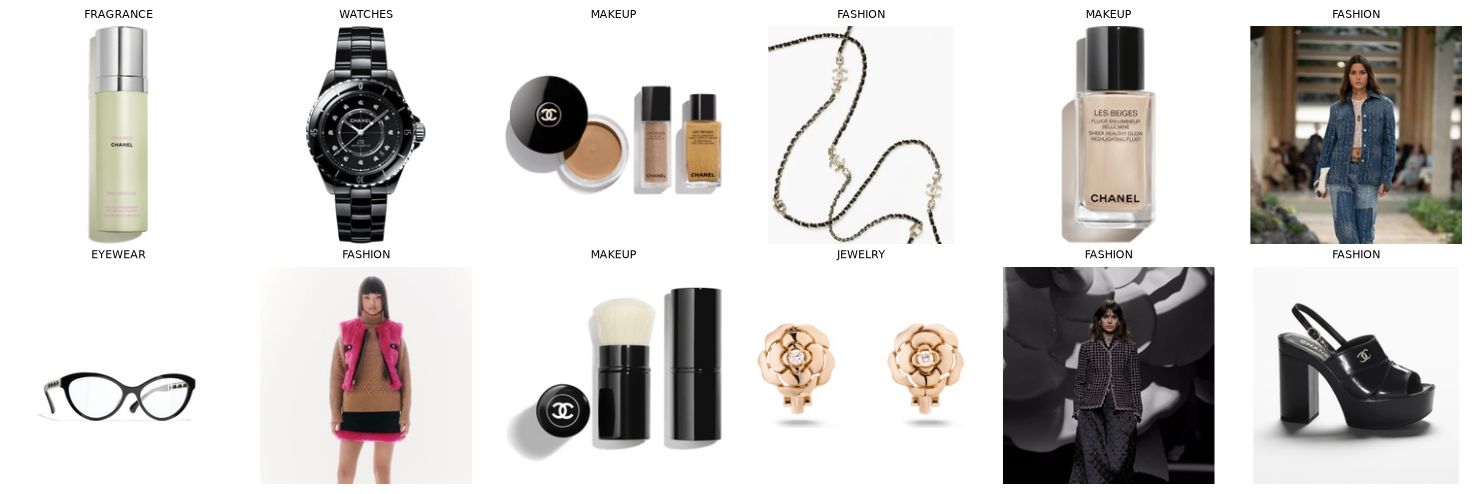

In [44]:
#redimensionnement 224x224 avec remplissage blanc
from PIL import ImageOps

def resize_pad(path, size=224):
    im = Image.open(path).convert("RGB")
    im.thumbnail((size, size), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), (255, 255, 255))
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return canvas

clean_img = clean[clean["has_image"]].copy()

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, (_, r) in zip(axes.ravel(), clean_img.sample(12, random_state=2).iterrows()):
    ax.imshow(resize_pad(r["image_path"]))
    ax.set_title(f'{r["category1_code"]}', fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [45]:
#on sauvegarde les images pré-traitées
PROC_DIR = DATA_DIR / "processed" / "images_224"
PROC_DIR.mkdir(parents=True, exist_ok=True)

def proc_path(p):
    return str(PROC_DIR / Path(p).name)

for p in clean_img["image_path"]:
    resize_pad(p).save(proc_path(p), "JPEG", quality=95)

clean["image_224_path"] = clean["image_path"].apply(lambda p: proc_path(p) if pd.notna(p) else None)
clean.loc[~clean["has_image"], "image_224_path"] = None
clean.to_csv(DATA_DIR / "processed" / "clean_dataset.csv", index=False)

print(len(list(PROC_DIR.glob("*.jpg"))), "images sauvegardées")

919 images sauvegardées


### Normalisation et augmentations

In [47]:
#normalisation
import torch
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

normalize_tf = transforms.Compose([
    transforms.ToTensor(),   #pixels 0-255 -> 0-1
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

x = normalize_tf(Image.open(clean_img.iloc[0]["image_224_path"]) if "image_224_path" in clean_img else resize_pad(clean_img.iloc[0]["image_path"]))
print("Forme du tenseur :", tuple(x.shape))
print("Min / max        :", x.min().item(), x.max().item())
print("Moyenne par canal:", x.mean(dim=(1, 2)))

Forme du tenseur : (3, 224, 224)
Min / max        : -1.843137264251709 2.640000104904175
Moyenne par canal: tensor([0.7940, 0.8316, 1.0531])


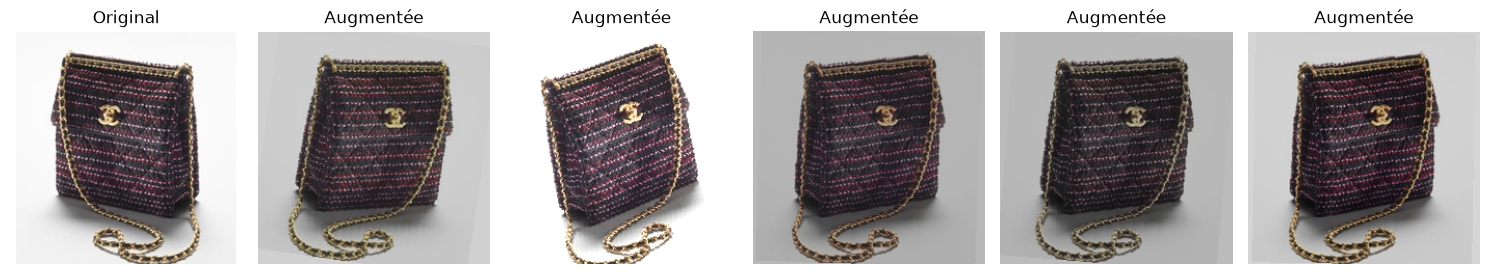

In [48]:
#augmentations(rotation, flip, color jitter)
augment_tf = transforms.Compose([
    transforms.RandomRotation(15, fill=(255, 255, 255)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
])

img0 = resize_pad(clean_img.iloc[0]["image_path"])

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img0); axes[0].set_title("Original")
for ax in axes[1:]:
    ax.imshow(augment_tf(img0)); ax.set_title("Augmentée")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()